# 🧱 Crack Classification Model — Bulging / Combined / Shear / Tension Crack
**Fine-grained classification of visually similar structural crack images using EfficientNet + advanced augmentation**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Install & Import Dependencies

In [2]:
!pip install timm albumentations torchvision torch scikit-learn matplotlib seaborn tqdm -q

In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from tqdm import tqdm
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

Using device: cuda


## 2. Configuration

In [4]:
# ============================================================
# CONFIG — Edit these paths to match your dataset structure
# ============================================================
DATA_ROOT   = '/content/drive/MyDrive/soil_dataset/TASK 1'   # Root folder with BULGING / COMBINED / SHEAR / TENSION CRACK subfolders
MODEL_SAVE  = './best_crack_model.pth'
FINAL_SAVE  = './crack_classifier_final.pth'

# Classes — must match subfolder names exactly
CLASSES     = ['BULGING', 'COMBINED', 'SHEAR', 'TENSION CRACK']
NUM_CLASSES = len(CLASSES)

# Training hyperparameters
IMG_SIZE    = 224
BATCH_SIZE  = 16       # Reduce to 8 if GPU OOM
EPOCHS      = 50
LR          = 1e-4
WEIGHT_DECAY= 1e-4
VAL_SPLIT   = 0.2
LABEL_SMOOTH= 0.1

# EfficientNet variant — 'efficientnet_b3' or 'efficientnet_b4' for stronger model
MODEL_NAME  = 'efficientnet_b3'

print(f'Classes: {CLASSES}')
print(f'Model: {MODEL_NAME}')
print(f'Image size: {IMG_SIZE}x{IMG_SIZE}')

Classes: ['BULGING', 'COMBINED', 'SHEAR', 'TENSION CRACK']
Model: efficientnet_b3
Image size: 224x224


## 3. Dataset Exploration

  BULGING: 100 images
  COMBINED: 118 images
  SHEAR: 117 images
  TENSION CRACK: 101 images

Total images: 436


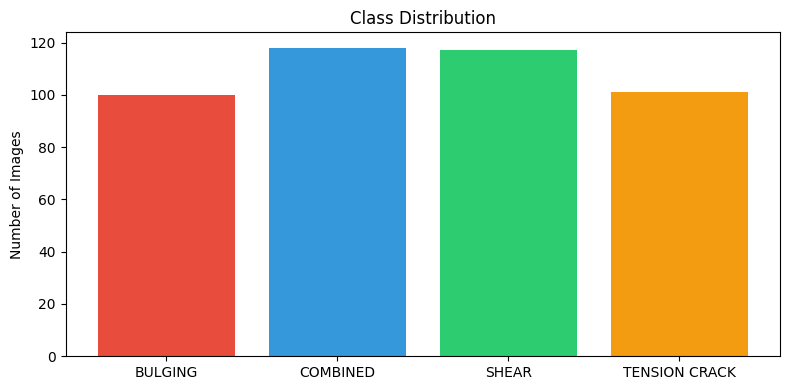

In [5]:
data_root = Path(DATA_ROOT)

# Collect all image paths and labels
all_images, all_labels = [], []
class_counts = {}

for idx, cls in enumerate(CLASSES):
    cls_path = data_root / cls
    if not cls_path.exists():
        print(f'⚠️  Folder not found: {cls_path}')
        continue
    imgs = list(cls_path.glob('**/*.jpg')) + list(cls_path.glob('**/*.jpeg')) + \
           list(cls_path.glob('**/*.png')) + list(cls_path.glob('**/*.bmp'))
    all_images += imgs
    all_labels += [idx] * len(imgs)
    class_counts[cls] = len(imgs)
    print(f'  {cls}: {len(imgs)} images')

print(f'\nTotal images: {len(all_images)}')

# Plot class distribution
plt.figure(figsize=(8, 4))
plt.bar(class_counts.keys(), class_counts.values(), color=['#e74c3c','#3498db','#2ecc71','#f39c12'])
plt.title('Class Distribution')
plt.ylabel('Number of Images')
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150)
plt.show()

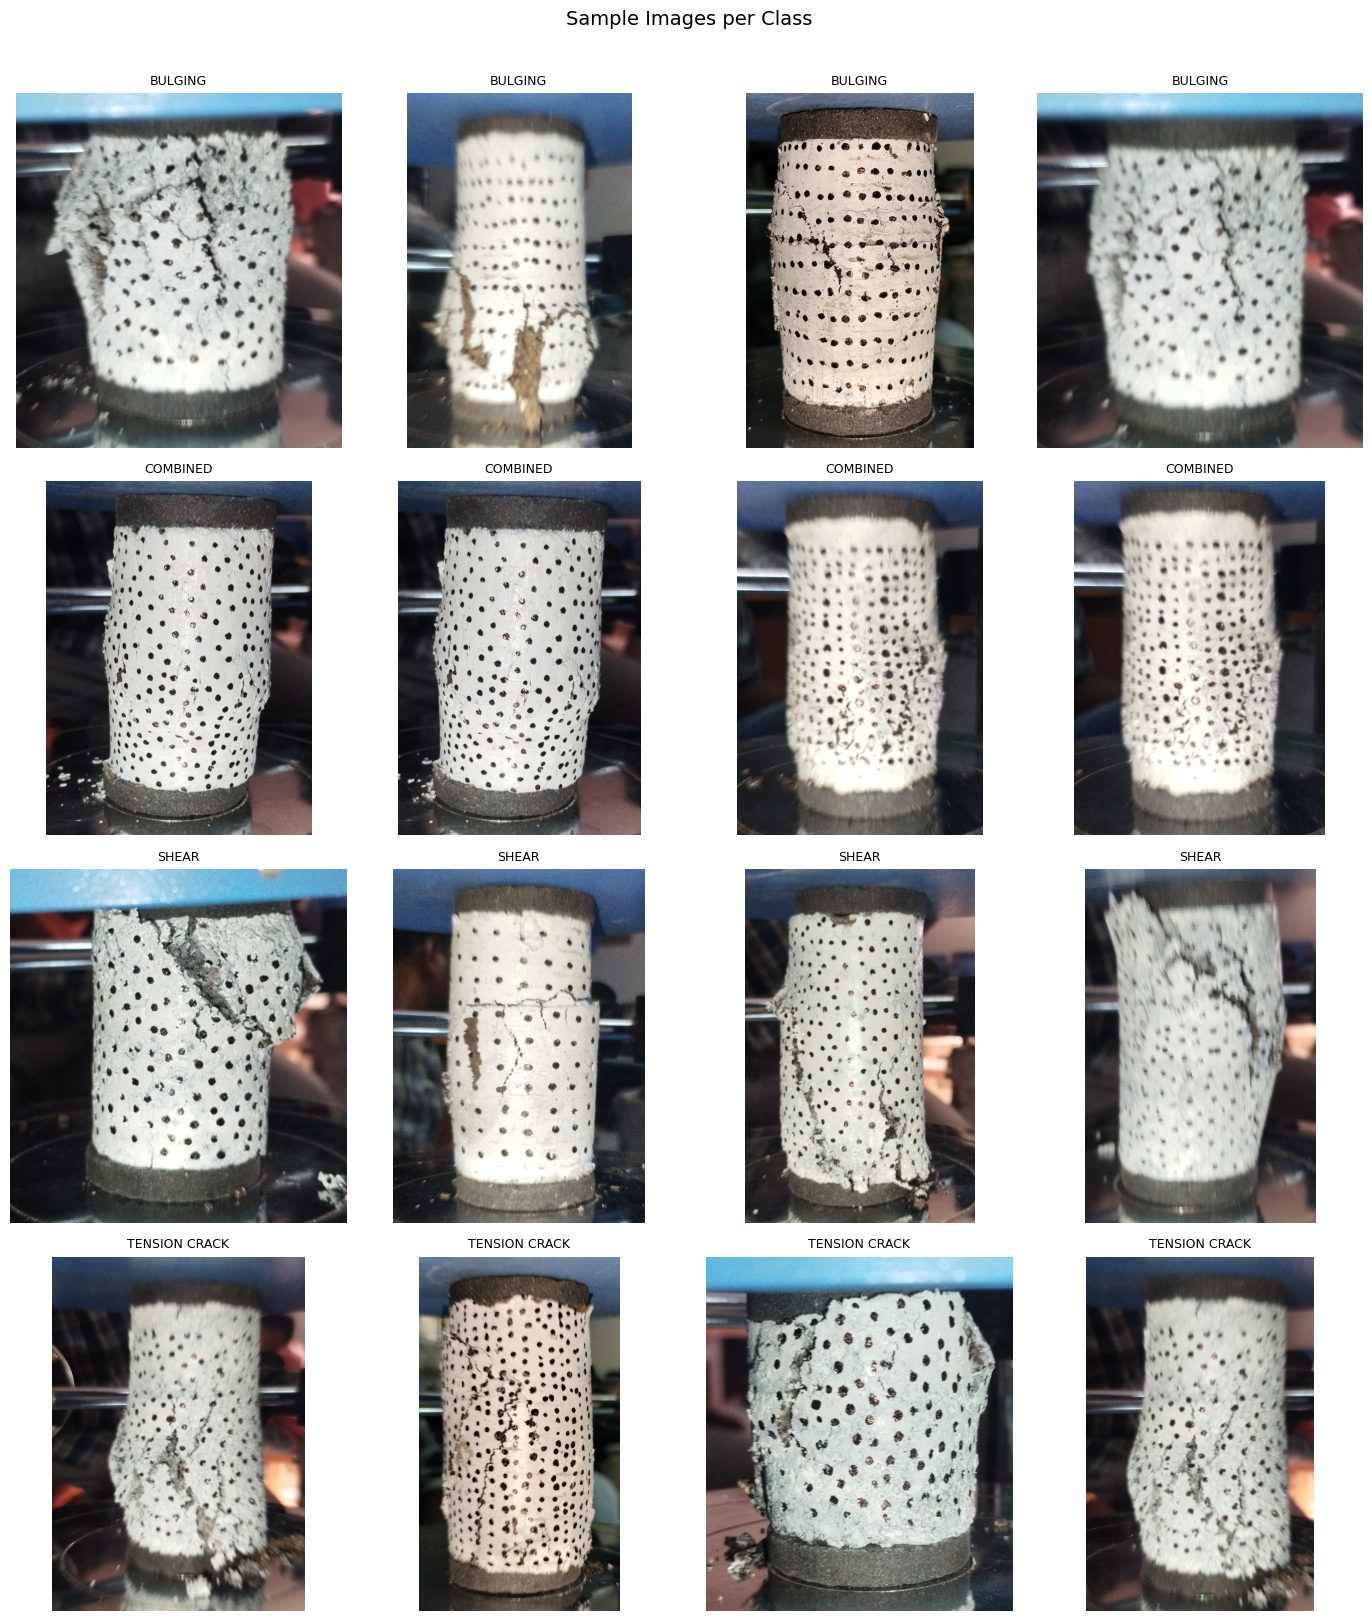

In [6]:
# Visualise sample images from each class
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(14, 4 * NUM_CLASSES))

for row, (cls_idx, cls_name) in enumerate(enumerate(CLASSES)):
    cls_imgs = [p for p, l in zip(all_images, all_labels) if l == cls_idx]
    samples = random.sample(cls_imgs, min(4, len(cls_imgs)))
    for col, img_path in enumerate(samples):
        img = Image.open(img_path).convert('RGB')
        axes[row][col].imshow(img)
        axes[row][col].set_title(f'{cls_name}', fontsize=9)
        axes[row][col].axis('off')

plt.suptitle('Sample Images per Class', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 4. Dataset & Augmentation

In [7]:
# -------------------------------------------------------
# Heavy augmentation for hard fine-grained classification
# -------------------------------------------------------

import albumentations as A
from albumentations.pytorch import ToTensorV2

# Detect albumentations version to handle API differences
import albumentations
_albu_ver = tuple(int(x) for x in albumentations.__version__.split('.')[:2])
print(f'Albumentations version: {albumentations.__version__}')

def make_transforms(img_size):
    # RandomResizedCrop: >=1.4 uses size=(h,w), older uses height=, width=
    if _albu_ver >= (1, 4):
        rrc = A.RandomResizedCrop(size=(img_size, img_size), scale=(0.7, 1.0))
        resize = A.Resize(height=img_size, width=img_size)
    else:
        rrc = A.RandomResizedCrop(height=img_size, width=img_size, scale=(0.7, 1.0))
        resize = A.Resize(height=img_size, width=img_size)

    # CoarseDropout: >=1.4 uses num_holes_range/hole_height_range, older uses max_holes etc.
    if _albu_ver >= (1, 4):
        dropout = A.CoarseDropout(num_holes_range=(4, 8), hole_height_range=(10, 20), hole_width_range=(10, 20), p=0.3)
    else:
        dropout = A.CoarseDropout(max_holes=8, max_height=20, max_width=20, p=0.3)

    # GaussNoise: >=1.4 uses std_range, older uses var_limit
    if _albu_ver >= (1, 4):
        gauss_noise = A.GaussNoise(std_range=(0.03, 0.1), p=1.0)
    else:
        gauss_noise = A.GaussNoise(var_limit=(10, 50), p=1.0)

    train_tf = A.Compose([
        rrc,
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.3),
        A.Rotate(limit=30, p=0.6),
        A.OneOf([
            gauss_noise,
            A.ISONoise(),
            A.MultiplicativeNoise()
        ], p=0.4),
        A.OneOf([
            A.MotionBlur(blur_limit=5),
            A.MedianBlur(blur_limit=5),
            A.GaussianBlur(blur_limit=5)
        ], p=0.3),
        A.OneOf([
            A.CLAHE(clip_limit=4.0),
            A.Sharpen(),
            A.Emboss()
        ], p=0.4),
        A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.1, p=0.5),
        A.RandomShadow(p=0.2),
        dropout,
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])

    val_tf = A.Compose([
        resize,
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])
    return train_tf, val_tf

train_transform, val_transform = make_transforms(IMG_SIZE)
print('Transforms ready.')

Albumentations version: 2.0.8
Transforms ready.


In [8]:
from sklearn.model_selection import train_test_split

class CrackDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels      = labels
        self.transform   = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = np.array(Image.open(self.image_paths[idx]).convert('RGB'))
        label = self.labels[idx]
        if self.transform:
            img = self.transform(image=img)['image']
        return img, label


# Stratified split
X_train, X_val, y_train, y_val = train_test_split(
    all_images, all_labels,
    test_size=VAL_SPLIT, stratify=all_labels, random_state=SEED
)

train_ds = CrackDataset(X_train, y_train, transform=train_transform)
val_ds   = CrackDataset(X_val,   y_val,   transform=val_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f'Train: {len(train_ds)} | Val: {len(val_ds)}')

Train: 348 | Val: 88


## 5. Class Weights (handle imbalance)

In [9]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=all_labels
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
print('Class weights:', dict(zip(CLASSES, class_weights.round(3))))

Class weights: {'BULGING': np.float64(1.09), 'COMBINED': np.float64(0.924), 'SHEAR': np.float64(0.932), 'TENSION CRACK': np.float64(1.079)}


## 6. Model — EfficientNet with Custom Head

In [10]:
class CrackClassifier(nn.Module):
    def __init__(self, model_name, num_classes, dropout=0.4):
        super().__init__()
        self.backbone = timm.create_model(
            model_name, pretrained=True, num_classes=0  # Remove original head
        )
        in_features = self.backbone.num_features
        self.classifier = nn.Sequential(
            nn.LayerNorm(in_features),
            nn.Dropout(dropout),
            nn.Linear(in_features, 512),
            nn.GELU(),
            nn.Dropout(dropout / 2),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        features = self.backbone(x)
        return self.classifier(features)


model = CrackClassifier(MODEL_NAME, NUM_CLASSES).to(DEVICE)
print(f'Model loaded: {MODEL_NAME}')
total_params = sum(p.numel() for p in model.parameters())
print(f'Total parameters: {total_params:,}')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]

Model loaded: efficientnet_b3
Total parameters: 11,488,300


## 7. Loss, Optimizer & Scheduler

In [11]:
# Label smoothing cross-entropy with class weights
criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor,
    label_smoothing=LABEL_SMOOTH
)

# Two-stage optimizer: head first, then full fine-tune
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# Cosine annealing with warm restarts
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-7
)

print('Criterion, Optimizer, Scheduler ready.')

Criterion, Optimizer, Scheduler ready.


## 8. Training Loop

In [12]:
from torch.cuda.amp import GradScaler, autocast

scaler = GradScaler(enabled=(DEVICE.type == 'cuda'))

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0


def run_epoch(model, loader, criterion, optimizer=None, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    pbar = tqdm(loader, desc='Train' if train else 'Val ', leave=False)

    with torch.set_grad_enabled(train):
        for imgs, labels in pbar:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)

            with autocast(enabled=(DEVICE.type == 'cuda')):
                outputs = model(imgs)
                loss    = criterion(outputs, labels)

            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * imgs.size(0)
            correct    += (outputs.argmax(1) == labels).sum().item()
            total      += imgs.size(0)
            pbar.set_postfix(loss=f'{loss.item():.4f}', acc=f'{correct/total:.3f}')

    return total_loss / total, correct / total


print('Starting training...')
print('=' * 60)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, train=True)
    vl_loss, vl_acc = run_epoch(model, val_loader,   criterion, optimizer=None, train=False)
    scheduler.step()

    history['train_loss'].append(tr_loss)
    history['train_acc'].append(tr_acc)
    history['val_loss'].append(vl_loss)
    history['val_acc'].append(vl_acc)

    flag = ''
    if vl_acc > best_val_acc:
        best_val_acc = vl_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': best_val_acc,
            'classes': CLASSES
        }, MODEL_SAVE)
        flag = '  ✅ Saved best'

    print(f'Epoch {epoch:03d}/{EPOCHS} | '
          f'Train Loss: {tr_loss:.4f}  Acc: {tr_acc:.4f} | '
          f'Val Loss: {vl_loss:.4f}  Acc: {vl_acc:.4f}{flag}')

print(f'\n🎉 Training complete! Best Val Acc: {best_val_acc:.4f}')

/tmp/ipykernel_9135/1691894573.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=(DEVICE.type == 'cuda'))


Starting training...


Train:   0%|          | 0/22 [00:00<?, ?it/s]/tmp/ipykernel_9135/1691894573.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(DEVICE.type == 'cuda')):


Epoch 001/50 | Train Loss: 1.3048  Acc: 0.4540 | Val Loss: 1.0832  Acc: 0.6705  ✅ Saved best


Epoch 002/50 | Train Loss: 1.1056  Acc: 0.5920 | Val Loss: 0.8159  Acc: 0.8409  ✅ Saved best


...

Epoch 046/50 | Train Loss: 0.4005  Acc: 0.9885 | Val Loss: 0.3623  Acc: 1.0000


Epoch 047/50 | Train Loss: 0.3760  Acc: 1.0000 | Val Loss: 0.3603  Acc: 1.0000


Epoch 048/50 | Train Loss: 0.3916  Acc: 0.9914 | Val Loss: 0.3606  Acc: 1.0000


Epoch 049/50 | Train Loss: 0.3812  Acc: 0.9943 | Val Loss: 0.3627  Acc: 1.0000


Epoch 050/50 | Train Loss: 0.3862  Acc: 0.9856 | Val Loss: 0.3607  Acc: 1.0000

🎉 Training complete! Best Val Acc: 1.0000


## 9. Training Curves

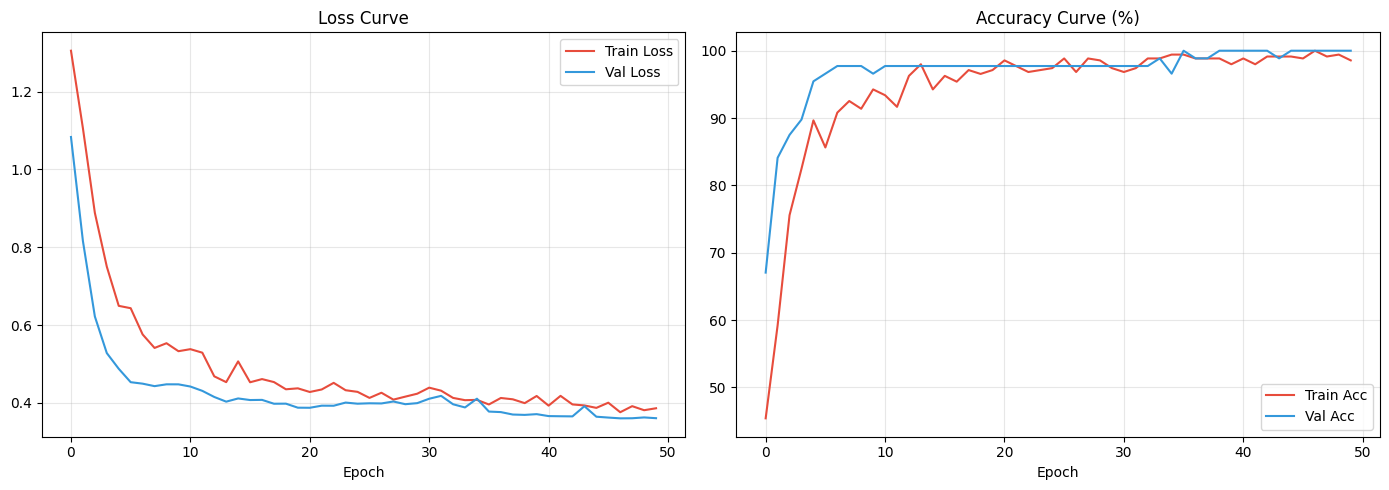

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history['train_loss'], label='Train Loss', color='#e74c3c')
ax1.plot(history['val_loss'],   label='Val Loss',   color='#3498db')
ax1.set_title('Loss Curve');  ax1.set_xlabel('Epoch');  ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot([a*100 for a in history['train_acc']], label='Train Acc', color='#e74c3c')
ax2.plot([a*100 for a in history['val_acc']],   label='Val Acc',   color='#3498db')
ax2.set_title('Accuracy Curve (%)'); ax2.set_xlabel('Epoch'); ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

## 10. Evaluation — Confusion Matrix & Classification Report

In [14]:
# Load best checkpoint
checkpoint = torch.load(MODEL_SAVE, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

all_preds, all_true = [], []

with torch.no_grad():
    for imgs, labels in tqdm(val_loader, desc='Evaluating'):
        imgs = imgs.to(DEVICE)
        outputs = model(imgs)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_true.extend(labels.numpy())

print('\n📊 Classification Report:')
print(classification_report(all_true, all_preds, target_names=CLASSES, digits=4))

Evaluating: 100%|██████████| 6/6 [00:02<00:00,  2.89it/s]


📊 Classification Report:
               precision    recall  f1-score   support

      BULGING     1.0000    1.0000    1.0000        20
     COMBINED     1.0000    1.0000    1.0000        24
        SHEAR     1.0000    1.0000    1.0000        24
TENSION CRACK     1.0000    1.0000    1.0000        20

     accuracy                         1.0000        88
    macro avg     1.0000    1.0000    1.0000        88
 weighted avg     1.0000    1.0000    1.0000        88



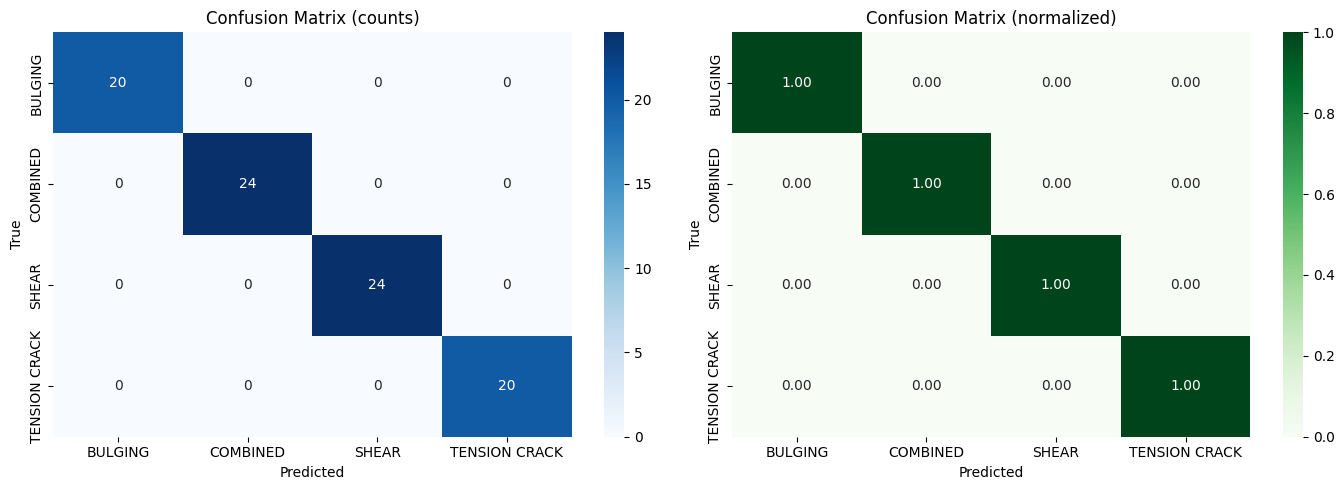

In [15]:
# Confusion Matrix
cm = confusion_matrix(all_true, all_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title('Confusion Matrix (counts)')
axes[0].set_ylabel('True'); axes[0].set_xlabel('Predicted')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title('Confusion Matrix (normalized)')
axes[1].set_ylabel('True'); axes[1].set_xlabel('Predicted')

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

## 11. Save Final Model (multiple formats)

In [16]:
# --- Full checkpoint (resume training) ---
torch.save({
    'model_name': MODEL_NAME,
    'num_classes': NUM_CLASSES,
    'classes': CLASSES,
    'img_size': IMG_SIZE,
    'model_state_dict': model.state_dict(),
    'best_val_acc': best_val_acc,
    'history': history
}, FINAL_SAVE)
print(f'✅ Full checkpoint saved → {FINAL_SAVE}')

# --- State dict only (lightweight inference) ---
torch.save(model.state_dict(), './crack_model_weights.pth')
print('✅ Weights only saved → crack_model_weights.pth')

# --- TorchScript (deployment) ---
model.eval()
scripted = torch.jit.script(model)
scripted.save('./crack_model_scripted.pt')
print('✅ TorchScript model saved → crack_model_scripted.pt')

✅ Full checkpoint saved → ./crack_classifier_final.pth
✅ Weights only saved → crack_model_weights.pth
✅ TorchScript model saved → crack_model_scripted.pt


## 12. Inference Helper

In [17]:
def load_model(checkpoint_path, device='cpu'):
    """Load the saved model for inference."""
    ckpt = torch.load(checkpoint_path, map_location=device)
    model = CrackClassifier(ckpt['model_name'], ckpt['num_classes'])
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()
    return model, ckpt['classes']


def predict_image(model, image_path, classes, img_size=224, device='cpu'):
    """Predict class for a single image."""
    transform = A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])
    img = np.array(Image.open(image_path).convert('RGB'))
    tensor = transform(image=img)['image'].unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(tensor)
        probs  = torch.softmax(logits, dim=1)[0].cpu().numpy()
        pred   = np.argmax(probs)

    print(f'Predicted: {classes[pred]} ({probs[pred]*100:.1f}%)')
    for i, (cls, p) in enumerate(zip(classes, probs)):
        bar = '█' * int(p * 30)
        print(f'  {cls:<18} {bar} {p*100:5.1f}%')

    return classes[pred], probs


# --- Example usage ---
# model_inf, classes_inf = load_model(FINAL_SAVE)
# predict_image(model_inf, 'test_crack.jpg', classes_inf)

## 13. Visualise Predictions on Validation Samples

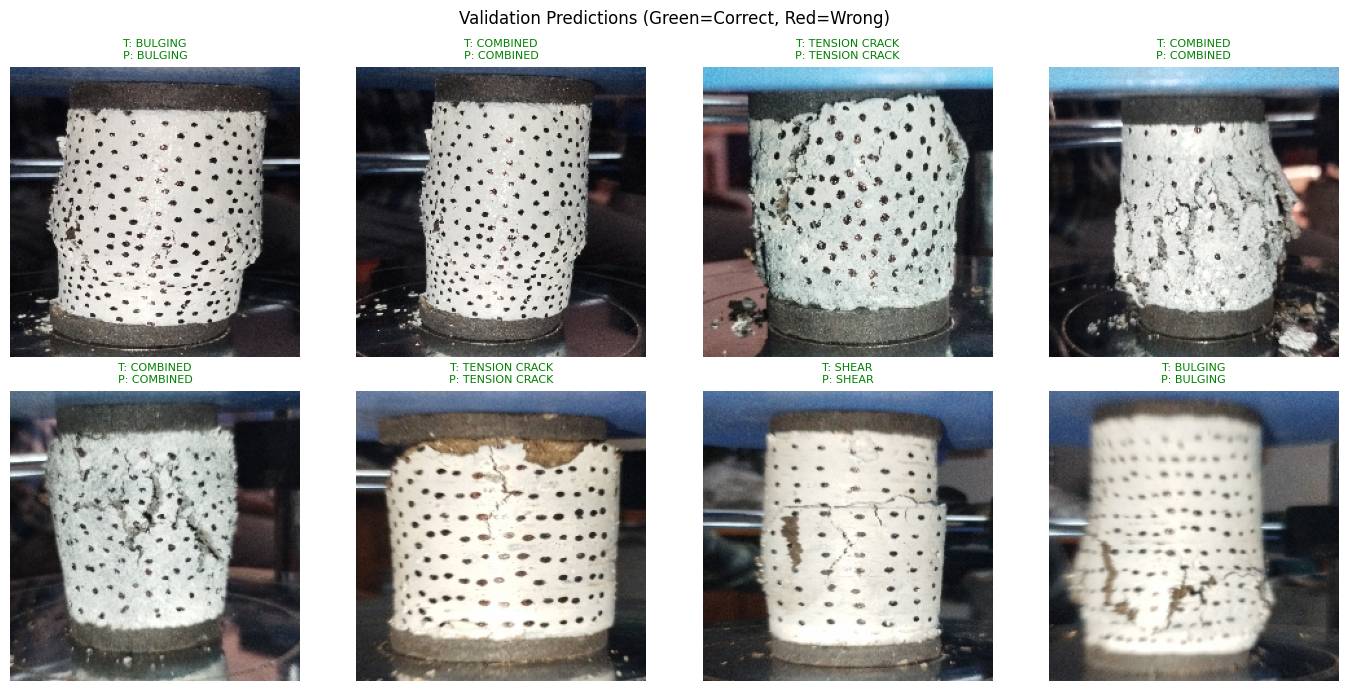

In [18]:
model.eval()
sample_imgs, sample_labels = next(iter(val_loader))
sample_imgs = sample_imgs.to(DEVICE)

with torch.no_grad():
    sample_preds = model(sample_imgs).argmax(1).cpu().numpy()

# Denormalize for display
mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])

n_show = min(8, len(sample_labels))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i in range(n_show):
    img = sample_imgs[i].cpu().permute(1, 2, 0).numpy()
    img = (img * std + mean).clip(0, 1)
    true_cls = CLASSES[sample_labels[i]]
    pred_cls = CLASSES[sample_preds[i]]
    color = 'green' if true_cls == pred_cls else 'red'
    axes[i].imshow(img)
    axes[i].set_title(f'T: {true_cls}\nP: {pred_cls}', color=color, fontsize=8)
    axes[i].axis('off')

plt.suptitle('Validation Predictions (Green=Correct, Red=Wrong)', fontsize=12)
plt.tight_layout()
plt.savefig('val_predictions.png', dpi=150)
plt.show()

---
## Summary

| Saved file | Purpose |
|---|---|
| `best_crack_model.pth` | Best checkpoint during training |
| `crack_classifier_final.pth` | Full metadata + weights for resuming |
| `crack_model_weights.pth` | Lightweight weights-only for inference |
| `crack_model_scripted.pt` | TorchScript for production deployment |

**Tips for improving accuracy further:**
- Collect more images per class (especially minority classes)
- Try `efficientnet_b4` or `convnext_base` as backbone
- Use Test-Time Augmentation (TTA) during inference
- Apply Grad-CAM to inspect what the model focuses on